# Analysis of the results (notebook 04)

Notebooks 02 and 03 run the models; this one only reads what they saved in 
and . Nothing is fitted here. It compares all models on the same five splits:
headline metrics, validation versus test, generalisation gap, per-seed spread, curves and
confusion matrices of seed 0, the training curves of the fine-tuned model, and which frauds
each model catches or misses.

Run time: under a minute.

In [1]:
import sys, os; os.chdir(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else None; sys.path.insert(0, "."); import warnings
import glob, json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

from modules import data_helper as dh
from modules import features as ft
from modules import results_helper as rh

DATA = "../data/fake_job_postings.csv"

In [2]:
SEED = 0
SPLIT_PATH = "splits/seed0.npz"
OUT_CLASSICAL = "outputs/classical"
OUT_DEEP = "outputs/deep"
GROUPS = ["classical", "deep"]

dh.seed_everything(SEED)
sns.set_theme(style="whitegrid")

In [3]:
DIRS = {"classical": OUT_CLASSICAL, "deep": OUT_DEEP}


class StopExecution(Exception):
    """Stops the notebook quietly when there is nothing to report."""

    def _render_traceback_(self):
        pass  # IPython hook: an empty traceback, so the notebook just stops

## Load the saved results

`results_helper.load_results` collects one row per (model, seed) from the JSON
files of the groups listed in `GROUPS` (deep results only when `outputs/deep/` is non-empty). If
nothing is found we stop here with a message instead of crashing.

In [4]:
# Result folders of the wanted groups that exist and are not empty.
dirs = [d for g, d in DIRS.items() if g in GROUPS and os.path.isdir(d) and os.listdir(d)]

# One row per (model, seed) from the saved json files.
res = rh.load_results(*dirs) if dirs else pd.DataFrame(columns=["group"])
res = res[res["group"].isin(GROUPS)]
if res.empty:
    print("No result files were found. Looked in:", dirs)
    print("Run the experiment cells of this notebook first, then re-run this section.")
    raise StopExecution
print(f"{len(res)} runs found: {res['model'].nunique()} models, "
      f"seeds {sorted(int(x) for x in res['seed'].unique())}")

40 runs found: 8 models, seeds [0, 1, 2, 3, 4]


## Which runs were found

Each cell counts finished runs; a full grid has exactly one run per (model, seed).

In [5]:
res.groupby(["model", "seed"]).size().unstack(fill_value=0)

seed,0,1,2,3,4
model,,,,,
cnb,1,1,1,1,1
dummy_majority,1,1,1,1,1
emb_logreg,1,1,1,1,1
logreg,1,1,1,1,1
logreg_bm25,1,1,1,1,1
mlp,1,1,1,1,1
ocsvm,1,1,1,1,1
tree,1,1,1,1,1


## Headline test metrics

Mean and standard deviation over seeds, sorted by mean test PR-AUC. The dummy rows
are the floor every real model has to beat. With a single seed there is no standard
deviation and only the mean is shown.

In [6]:
def fmt(col):
    """mean +- std over seeds for one metric; a lone seed has no std."""
    g = res.groupby("model")[col]
    return [f"{m:.3f} +- {s:.3f}" if pd.notna(s) else f"{m:.3f}"
            for m, s in zip(g.mean(), g.std())]


# Models ordered by mean test PR-AUC, best first.
order = res.groupby("model")["test_pr_auc"].mean().sort_values(ascending=False).index

# The headline table: mean +- std over seeds.
pd.DataFrame({
    "seeds": res.groupby("model").size(),
    "test PR-AUC": fmt("test_pr_auc"),
    "test F1": fmt("test_f1"),
    "test precision": fmt("test_precision"),
    "test recall": fmt("test_recall"),
}).loc[order]

,seeds,test PR-AUC,test F1,test precision,test recall
model,,,,,
logreg_bm25,5,0.847 +- 0.073,0.804 +- 0.055,0.856 +- 0.034,0.760 +- 0.081
mlp,5,0.846 +- 0.077,0.787 +- 0.081,0.863 +- 0.051,0.726 +- 0.106
logreg,5,0.821 +- 0.063,0.772 +- 0.042,0.827 +- 0.052,0.726 +- 0.053
cnb,5,0.773 +- 0.029,0.697 +- 0.029,0.842 +- 0.044,0.598 +- 0.050
emb_logreg,5,0.524 +- 0.060,0.520 +- 0.028,0.551 +- 0.049,0.495 +- 0.044
tree,5,0.402 +- 0.066,0.501 +- 0.055,0.434 +- 0.054,0.634 +- 0.165
ocsvm,5,0.057 +- 0.009,0.081 +- 0.020,0.063 +- 0.035,0.202 +- 0.156
dummy_majority,5,0.049 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.000 +- 0.000


The dummy predicts "real" for every ad: precision, recall and F1 are 0 and its PR-AUC equals the
share of fraud in the data, the floor every real model has to beat.

## Validation vs test PR-AUC

Validation is what models, hyper-parameters and thresholds were chosen on; test is
the honest number. The difference is the price of that selection.

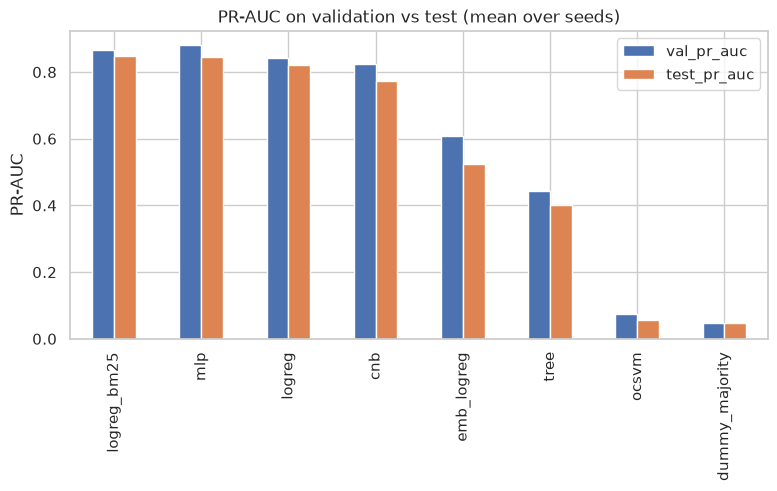

In [7]:
# Mean validation and test PR-AUC per model, then grouped bars.
means = res.groupby("model")[["val_pr_auc", "test_pr_auc"]].mean().loc[order]
ax = means.plot(kind="bar", figsize=(9, 4))
ax.set_title("PR-AUC on validation vs test (mean over seeds)")
ax.set_xlabel("")
ax.set_ylabel("PR-AUC")
plt.show()

Reading: each model has two bars, validation and test, on the same 0 to 1 scale;
the validation bar tends to sit at or above the test bar.

## Generalisation gap

Train PR-AUC minus test PR-AUC per model (mean over seeds). A large gap means the
model memorised its training rows.

In [8]:
g = res.groupby("model").agg(train_pr_auc=("train_pr_auc", "mean"),
                             test_pr_auc=("test_pr_auc", "mean"))
g["gap (train - test)"] = g["train_pr_auc"] - g["test_pr_auc"]
g.sort_values("gap (train - test)", ascending=False)

,train_pr_auc,test_pr_auc,gap (train - test)
model,,,
tree,0.638283,0.402411,0.235873
emb_logreg,0.713466,0.524291,0.189175
logreg,0.991778,0.820640,0.171139
cnb,0.931241,0.772621,0.158620
logreg_bm25,1.000000,0.847136,0.152864
mlp,0.992673,0.846210,0.146463
ocsvm,0.078260,0.056689,0.021571
dummy_majority,0.048679,0.048580,0.000099


## Per-seed spread

Session 7 rule of thumb: a model that wins by less than its own standard deviation
has not won. Each point is one split seed.

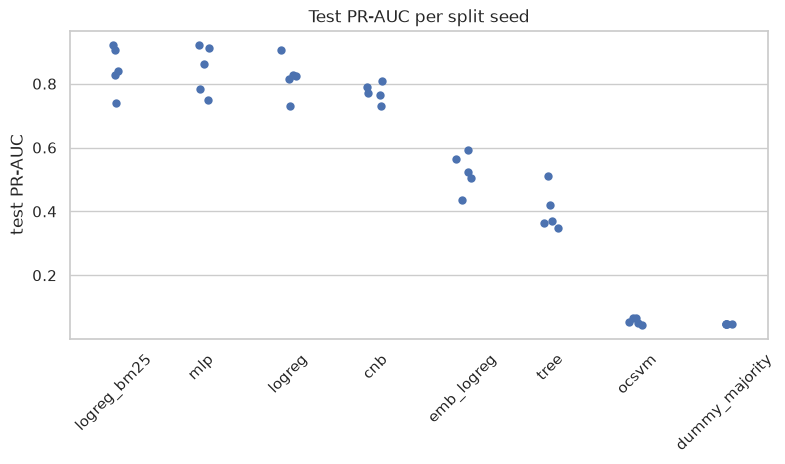

In [9]:
# One point per (model, seed).
fig, ax = plt.subplots(figsize=(9, 4))
sns.stripplot(data=res, x="model", y="test_pr_auc", order=order, ax=ax, size=6)
ax.set_title("Test PR-AUC per split seed")
ax.set_xlabel("")
ax.set_ylabel("test PR-AUC")
ax.tick_params(axis="x", rotation=45)
plt.show()

Reading: every point is one seed of one model; models whose point clouds overlap
are indistinguishable at this level of noise.

## Seed 0 in detail

The NPZ files hold y and scores for validation and test in the same row order as the
split, so curves and matrices can be rebuilt without refitting anything. If no
seed-0 run exists we stop with a message.

In [10]:
# Stop quietly when there is no seed-0 run.
seed0 = res[res["seed"] == 0]
if seed0.empty:
    print("No seed-0 runs found; the remaining sections need seed 0.")
    raise StopExecution

# Saved scores and threshold of every seed-0 model; y_test is the same for all of them.
seed_runs = {row["model"]: (rh.load_scores(DIRS[row["group"]], row["model"], 0), row["thr"])
             for _, row in seed0.iterrows()}
y_test = next(iter(seed_runs.values()))[0]["y_test"]
print("seed-0 models:", ", ".join(seed_runs))

seed-0 models: cnb, dummy_majority, logreg_bm25, logreg, mlp, ocsvm, tree, emb_logreg


### Precision-recall curves on the test split (seed 0)

Built from the saved scores with sklearn's `precision_recall_curve`; the dashed line
is the fraud base rate, i.e. what random guessing scores.

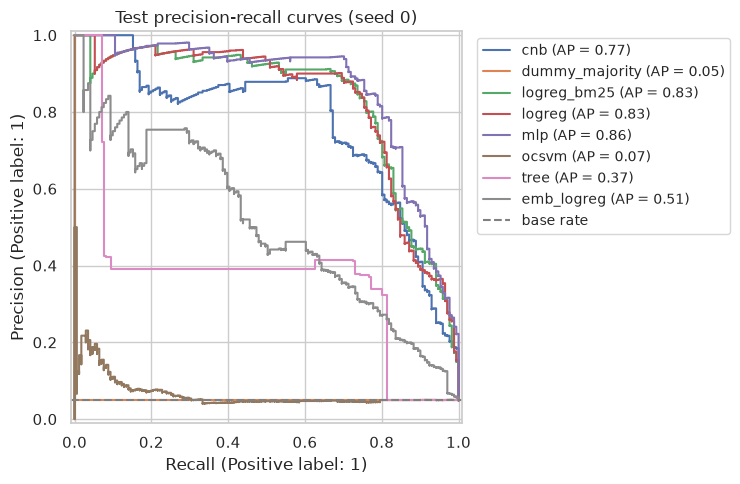

In [11]:
# One curve per model, rebuilt from the saved test scores, on shared axes.
fig, ax = plt.subplots(figsize=(9, 5))
for name, (s, thr) in seed_runs.items():
    PrecisionRecallDisplay.from_predictions(y_test, s["score_test"], name=name, ax=ax)

# Base rate: what random guessing scores.
ax.axhline(float(y_test.mean()), linestyle="--", color="grey", label="base rate")
ax.set_title("Test precision-recall curves (seed 0)")

# Legend outside the axes, to the right, so it does not cover the curves.
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize="small")
fig.tight_layout()
plt.show()

Reading: the x axis is recall, the y axis precision; closer to the top-right corner
is better, and the dashed grey line is the base rate every curve should beat.

### Confusion matrices at the validation-chosen threshold (seed 0)

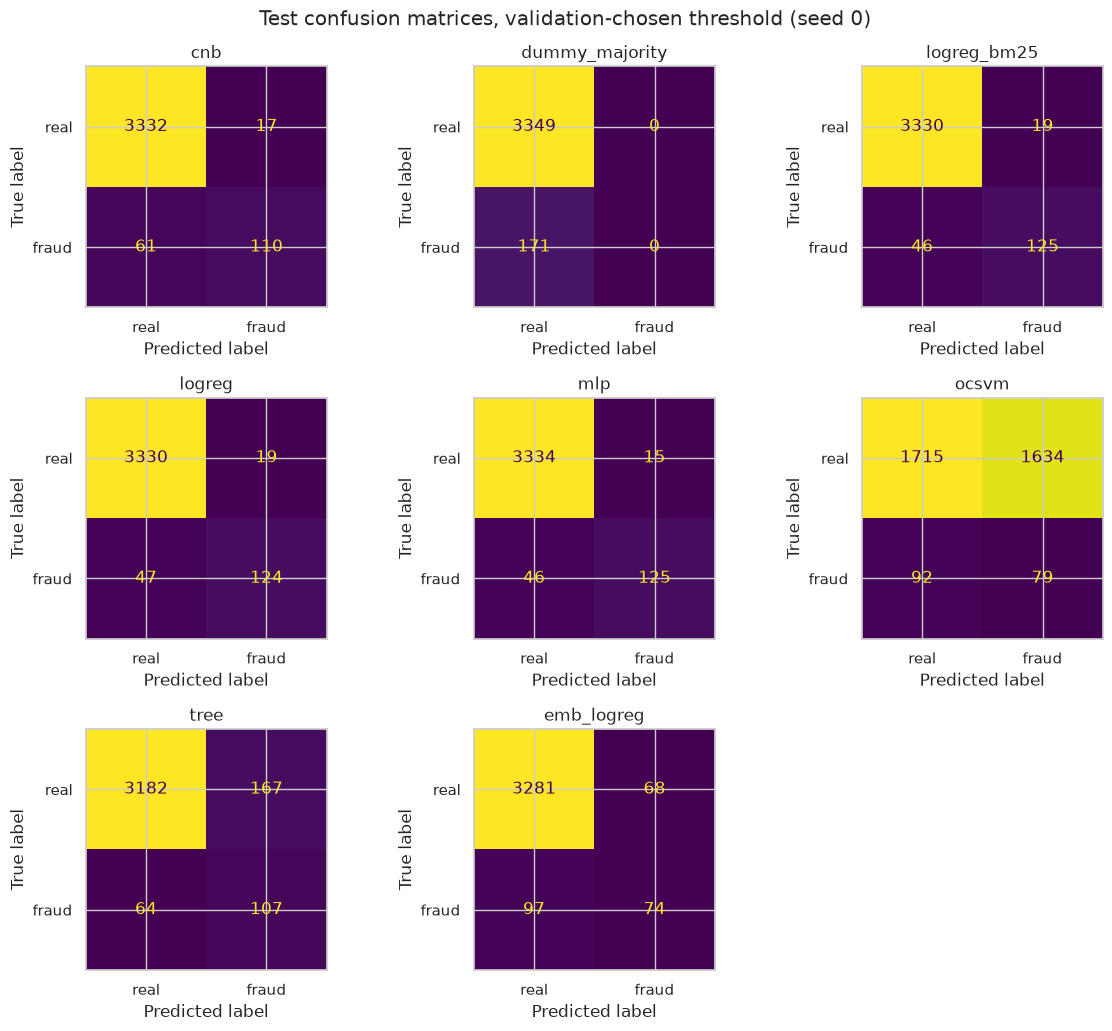

In [12]:
# Grid of panels, 3 per row, one per model.
n_cols = 3
n_rows = -(-len(seed_runs) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows), squeeze=False)

# Hard predictions at each model's own validation-chosen threshold.
for ax, (name, (s, thr)) in zip(axes.ravel(), seed_runs.items()):
    pred = (s["score_test"] >= thr).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["real", "fraud"],
                                            colorbar=False, ax=ax)
    ax.set_title(name)

# Hide unused panels.
for ax in axes.ravel()[len(seed_runs):]:
    ax.set_visible(False)
fig.suptitle("Test confusion matrices, validation-chosen threshold (seed 0)")
fig.tight_layout()
plt.show()

Reading: rows are the actual class, columns the predicted class; the diagonal holds
the correct calls.

## Fit time per model

Wall-clock seconds per run (mean over seeds and slowest seed), as recorded by the
runners.

In [13]:
res.groupby("model")["seconds"].agg(["mean", "max"]).sort_values("mean").round(1)

,mean,max
model,,
dummy_majority,0.0,0.0
emb_logreg,1.1,2.1
logreg,60.8,70.3
cnb,73.9,74.7
logreg_bm25,78.6,80.0
tree,88.6,91.0
ocsvm,114.3,123.5
mlp,439.7,483.1


## Which frauds does each model catch? (seed 0)

At each model's own validation-chosen threshold: how many of the test frauds does
model A catch that model B misses. Plus the frauds caught by at least one model but
not by all.

In [14]:
# Which test frauds each model catches at its own threshold.
SKIP_CATCH = ("dummy_majority", "ocsvm")
fraud_idx = np.where(y_test == 1)[0]
# Left out: the dummy flags nothing, and the one-class SVM flags about half of all ads,
# so it "catches" frauds by flagging everything near them.
caught = {name: frozenset(fraud_idx[s["score_test"][fraud_idx] >= thr])
          for name, (s, thr) in seed_runs.items() if name not in SKIP_CATCH}

# Pairwise matrix: frauds caught by the row model but missed by the column model.
names = list(caught)
overlap = pd.DataFrame(0, index=names, columns=names)
for a in names:
    for b in names:
        overlap.loc[a, b] = len(caught[a] - caught[b])

# Frauds caught by at least one model but not by all (union minus intersection).
union = set().union(*caught.values())
inter = set(fraud_idx)
for c in caught.values():
    inter &= c
print("test frauds caught by at least one model but not by all:", len(union - inter))
overlap

test frauds caught by at least one model but not by all: 81


,cnb,logreg_bm25,logreg,mlp,tree,emb_logreg
cnb,0,2,3,3,21,44
logreg_bm25,17,0,1,4,31,55
logreg,17,0,0,3,31,54
mlp,18,4,4,0,34,56
tree,18,13,14,16,0,40
emb_logreg,8,4,4,5,7,0


Reading: cell (A, B) counts test frauds caught by A but missed by B, so the
diagonal is zero by construction; rows with large values catch much that the column
models let through.

## The ads nobody catches (seed 0)

The last Session 6 step: read the test frauds that no model flagged at its own
threshold. These are the target for the next iteration. This cell needs the seed-0
split file to look the rows up.

In [15]:
if not os.path.exists(SPLIT_PATH):
    print("splits/seed0.npz not found; cannot look up the missed ads.")
else:
    # The seed-0 test rows, in the same order as the saved scores.
    df = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))
    test = df.iloc[dh.load_splits(SPLIT_PATH, df)["test"]]

    # Ads flagged by at least one real model at its own threshold.
    caught_any = np.zeros(len(test), dtype=bool)
    for name, (s, thr) in seed_runs.items():
        if name not in SKIP_CATCH:            # see the cell above for why these two are left out
            caught_any |= (s["score_test"] >= thr)

    # The frauds nobody caught, printed for reading.
    missed = test[(y_test == 1) & ~caught_any]
    print(len(missed), "test frauds that no model caught:")
    for _, r in missed.iterrows():
        print("-", str(r["title"])[:80], "|", str(r["description"])[:150], "\n")

26 test frauds that no model caught:
-  JOB VACANCIES AT MONTCALM LUXURY HOTEL LONDON. | Montcalm Luxury Hotel London34-40 Great Cumberland Pl Marble Arch, London W1H 7TW, United KingdomTelephone: #PHONE_12f88d70e2cf3375f39a78f81729c0e76eb 

- Urgent Requirement For The Position Technical Lead - Rhomobile Technical Mobilit | 1.    Technical Lead - Rhomobile Technical Mobility Lead Developer  NOTES-  In case if Rhomobile is difficult to find, Please find people with experti 

- Customer Assistant | Every project we deal with involves many different specialists. Their talent and knowledge, skills and enthusiasm help us to find the solution even in 

- software development life cycle |   Title: Service Desk ResourceLocation: Atlanta, GADuration: Long Term Position Description: The position of Senior Software Developer for the Service 

- Licensed Life Insurance Agent | We need someone who is smart, funny, great with people, wants to make a difference and also make great money...is that yo

## Training curves of the fine-tuned model

Session 7: read the curve, not only the end number. Per epoch validation PR-AUC and training
loss, from the `history` stored with each saved run.

In [16]:
import glob, json

# One row per (seed, epoch) from the history stored in each saved fine-tuning run.
rows = []
for path in sorted(glob.glob(os.path.join(OUT_DEEP, "bert_*_seed*.json"))):
    with open(path, encoding="utf-8") as f:
        rec = json.load(f)
    for h in rec.get("history", []):
        rows.append({"seed": rec["seed"], **h})
hist = pd.DataFrame(rows)

if hist.empty:
    print("no fine-tuning history found yet")
else:
    # Left: validation PR-AUC per epoch. Right: training loss per epoch. One line per seed.
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for seed, g in hist.groupby("seed"):
        axes[0].plot(g["epoch"], g["val_pr_auc"], marker="o", label=f"seed {seed}")
        axes[1].plot(g["epoch"], g["train_loss"], marker="o", label=f"seed {seed}")
    axes[0].set_title("Validation PR-AUC per epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("PR-AUC")
    axes[1].set_title("Training loss per epoch"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("weighted cross-entropy")
    axes[0].legend()
    plt.show()

    # Time per epoch decides whether to run all five seeds.
    print("seconds per epoch:", hist["seconds"].round(0).tolist())

no fine-tuning history found yet


## Explaining DistilBERT, part 1: where it disagrees with TF-IDF logistic regression (seed 0)

Error analysis from the saved test scores only, nothing is refitted. At each model's own
validation-chosen threshold: the frauds one model catches and the other misses, and the real ads
DistilBERT is most sure are fraud (its most confident false alarms).

In [17]:
bert_name = next((n for n in seed_runs if n.startswith("bert_")), None)
if bert_name is None or "logreg" not in seed_runs or not os.path.exists(SPLIT_PATH):
    print("needs seed-0 runs of DistilBERT and logreg, and splits/seed0.npz")
else:
    df = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))
    test = df.iloc[dh.load_splits(SPLIT_PATH, df)["test"]].reset_index(drop=True)

    # Hard predictions of both models at their own thresholds.
    (sb, tb), (sl, tl) = seed_runs[bert_name], seed_runs["logreg"]
    flag_b, flag_l = sb["score_test"] >= tb, sl["score_test"] >= tl
    fraud = y_test == 1

    def titles(mask, k=8):
        for _, r in test[mask].head(k).iterrows():
            print("   -", str(r["title"])[:70], "|", str(r["description"])[:80])

    print(f"frauds caught by DistilBERT only: {int((fraud & flag_b & ~flag_l).sum())}")
    titles(fraud & flag_b & ~flag_l)
    print(f"frauds caught by logreg only: {int((fraud & flag_l & ~flag_b).sum())}")
    titles(fraud & flag_l & ~flag_b)

    # The real ads with the highest DistilBERT scores.
    worst = np.argsort(-np.where(fraud, -np.inf, sb["score_test"]))[:5]
    print("DistilBERT's most confident false alarms:")
    for i in worst:
        print(f"   - score {sb['score_test'][i]:.3f} |", str(test.loc[i, "title"])[:70])

needs seed-0 runs of DistilBERT and logreg, and splits/seed0.npz


## Explaining DistilBERT, part 2: which words pushed it towards fraud (Integrated Gradients)

Computed on the server right after training seed 0 (notebook 03): for 10 test ads, Integrated
Gradients measures how much each token moved the fraud probability compared with an all-[PAD]
version of the same ad. Word pieces (`##...`) are merged back into words. Listed: the 8 words with
the largest push towards fraud.

In [18]:
paths = sorted(glob.glob(os.path.join(OUT_DEEP, "bert_*_explain_seed0.json")))
if not paths:
    print("no explanation file yet; it is written by the DistilBERT run of notebook 03")
else:
    with open(paths[0], encoding="utf-8") as f:
        explained = json.load(f)
    for r in explained:
        # Merge word pieces into words and drop the special tokens.
        words, attrs = [], []
        for t, a in zip(r["tokens"], r["attributions"]):
            if t in ("[CLS]", "[SEP]", "[PAD]"):
                continue
            if t.startswith("##") and words:
                words[-1] += t[2:]
                attrs[-1] += a
            else:
                words.append(t)
                attrs.append(a)
        top = [w for a, w in sorted(zip(attrs, words), reverse=True)[:8] if a > 0]
        print(f"[{r['kind']}] score {r['score']:.3f}: " + ", ".join(top))

no explanation file yet; it is written by the DistilBERT run of notebook 03


Reading: a word listed for a missed fraud still pushed towards fraud, just not enough to cross
the threshold; words for a false alarm show what misled the model.

## Findings (classical models)

Numbers are test PR-AUC, means over the 5 split seeds in the first table.

- Every supervised text model beats the dummy floor (0.049) by a wide margin: 0.77 to 0.85, except
  the single decision tree (0.40).
- Logistic regression with TF-IDF (0.821), with BM25 (0.847) and the MLP (0.846) are within seed
  noise of each other: the spread across seeds (std about 0.06 to 0.08) is larger than the gaps
  between them. The MLP costs about 7 minutes per seed against 1 to 1.5 for the logistic regressions.
- Complement Naive Bayes reaches 0.773: below TF-IDF logistic regression on 4 of 5 seeds (mean
  difference -0.048), but with the smallest spread across seeds of any supervised model (std 0.029).
- The one-class SVM, trained on real ads only, scores 0.057 (ROC-AUC 0.47), no better than the
  dummy. A supervised logistic regression on the same SVD features does far better (part A of
  notebook 02), so the signal is in the features: fraudulent ads are simply not unusual ads. This is
  why the project treats the task as supervised classification, not anomaly detection.
- Train minus test PR-AUC is 0.15 to 0.17 for the logistic regressions, the MLP and Naive Bayes,
  and 0.24 for the tree: all of them fit their training rows much better than unseen ads.
- Caveat: the dataset marks real ads from some countries (for example Greece) as 0%
  fraud, so part of the signal may come from how the data was collected.

## Findings (deep models)

Pending: DistilBERT is being rerun on the GPU server (its classification head is now seeded, so
the five seeds are reproducible) together with the new zero-shot language model. The findings are
written from those results once they are back.